# [기초-실습] 통계 101×데이터 분석: (4장) 추론통계~신뢰구간

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 표본조사 체험하기

**📘 문제**

- 온라인 쇼핑몰은 전체 고객 수가 너무 많아, 모든 고객을 조사하기 어렵습니다.

- 그래서 무작위로 고객 30명을 뽑아 평균 만족도를 계산하고 이를 전체 만족도의 추정값으로 사용하려 합니다.

- 이번 실습에서는 직접 표본을 뽑고, 표본 평균을 구해보며,
  **“표본마다 결과가 달라질 수 있다”**는 추론 통계의 핵심 개념을 체험해봅니다.

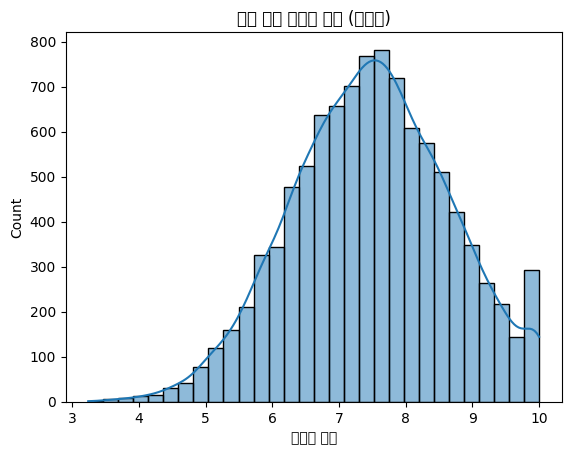

In [3]:
# 모집단 생성 (전체 고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.5, scale=1.2, size=10000)
population = np.clip(population, 1, 10)  # 1점 ~ 10점 사이로 제한
df_pop = pd.DataFrame({'score': population})

# 전체 모집단 시각화
sns.histplot(df_pop['score'], bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 표본을 무작위로 여러 번 뽑아 보고, 표본 평균이 어떻게 변하는지 확인해봅시다.

- 히스토그램을 그리고, 표본 평균의 분포 형태를 관찰해봅시다.

In [4]:
# [문제 1] Q1. 모집단에서 무작위로 30명을 뽑아 표본 평균을 구해봅시다.
# 여기에 코드를 작성해주세요.
sample = df_pop['score'].sample(n=30)

# 표본 평균 계산
sample_mean = sample.mean()
print(f"표본 평균: {sample_mean:.3f}")
print(f"모집단 평균: {df_pop['score'].mean():.3f}")

표본 평균: 7.202
모집단 평균: 7.481


In [5]:
# [문제 1] Q2. 이 과정을 500번 반복하고, 표본 평균을 리스트에 저장합니다.
# 여기에 코드를 작성해주세요.
sample_means = []  # 표본 평균을 저장할 리스트

for i in range(500):
    sample = df_pop['score'].sample(n=30)
    sample_means.append(sample.mean())

print(f"저장된 표본 평균 개수: {len(sample_means)}")
print(f"처음 5개: {[round(m, 3) for m in sample_means[:5]]}")

저장된 표본 평균 개수: 500
처음 5개: [np.float64(7.218), np.float64(7.576), np.float64(7.603), np.float64(7.259), np.float64(7.559)]


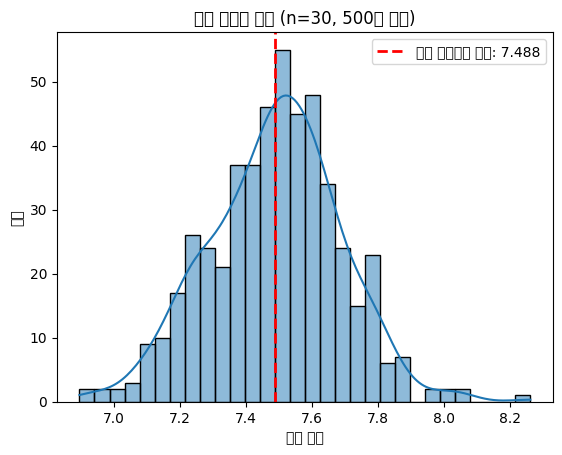

In [6]:
# [문제 1] Q3. 표본 평균들의 분포를 히스토그램으로 그려봅시다. 평균선도 함께 표시해 봅시다.
# 여기에 코드를 작성해주세요.
mean_of_means = np.mean(sample_means)

sns.histplot(sample_means, bins=30, kde=True)
plt.axvline(mean_of_means, color='red', linestyle='--', linewidth=2,
            label=f"표본 평균들의 평균: {mean_of_means:.3f}")
plt.title("표본 평균의 분포 (n=30, 500회 반복)")
plt.xlabel("표본 평균")
plt.ylabel("빈도")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 평균들은 어떤 값 주변에 많이 분포해 있나요? 이 값은 전체 모집단 평균과 얼마나 비슷한가요?

- 표본을 1번 뽑았을 때와 500번을 반복해서 뽑았을 때, 표본 평균의 분포나 신뢰성에는 어떤 차이가 있나요

- 친구가 다른 표본을 뽑았다면 같은 평균이 나왔을까요? 비슷한 결과가 나왔더라도 완전히 같지 않았다면, 그 이유는 무엇일까요?

- 표본 평균들의 분포는 어떤 모양인가요? 종 모양의 정규분포처럼 보이나요? 그렇다면 왜 그렇게 되는 걸까요?

In [7]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 1. 7.5 근처에 몰려있고, 표본평균들의 평균은 모집단의 평균과 비슷하다. 
# 2. 1번 뽑으면 그 값이 정확한지는 알 수 없다. 500번 반복하면 표본 평균이 얼마나 흔들리는지를 알 수 있어서
#    표본 하나의 신뢰도를 판단할 근거가 생깁니다.
# 3. 비슷한 결과가 나오지만 완전히 같지는 않다. 표본을 뽑을 때 마다 다른 확률이 나오므로 이를 표본오차라한다.
# 4. 표본크기가 커질수록 중심극한정리에 의해 정규분포로 근사한다.

# 문제 2. 중심극한정리

**📘 문제**

- 현실에서는 모집단의 분포가 정규분포가 아닐 수도 있습니다.

- 예를 들어, 일부 고객은 매우 높은 점수를 주고, 대부분은 낮은 점수를 주는 만족도 분포가 있을 수 있죠. (예: 지수분포)

- 이처럼 원래 분포가 비정규분포여도,
  표본을 여러 번 뽑아 평균을 계산하면, 그 평균들의 분포는 정규분포에 가까워진다는 것을
  **중심극한정리(Central Limit Theorem)**라고 합니다.

- 이번 실습에서는 다양한 크기의 표본을 뽑아 평균을 계산하고,
  그 평균들의 분포가 어떻게 변하는지를 직접 실험해 봅니다.

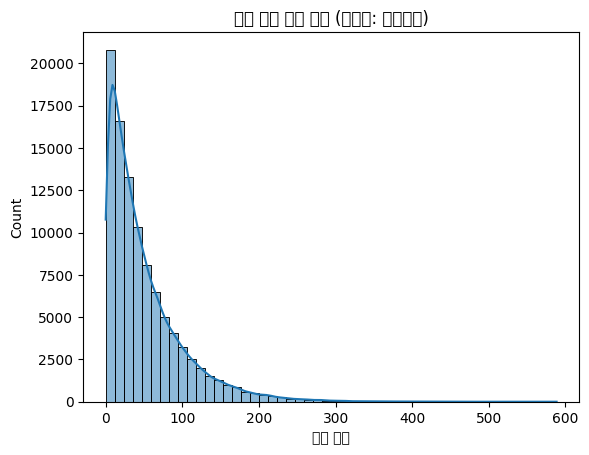

In [8]:
# 지수분포를 따르는 모집단 생성
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포

# 모집단 시각화
sns.histplot(population, bins=50, kde=True)
plt.title("고객 구매 금액 분포 (모집단: 지수분포)")
plt.xlabel("구매 금액")
plt.show()

**📌 아래를 수행해 보세요:**

- 비대칭적인 모집단(지수분포)에서 무작위로 표본을 추출해 평균을 구해봅시다.

- 표본 크기를 바꿔가며, 표본 평균들의 분포가 어떻게 변화하는지 확인해봅시다.

- 히스토그램을 그리고, 분포의 모양을 관찰해봅시다.

- 표본 크기가 커질수록 표본 평균 분포의 모양과 **퍼진 정도(분산)**가 어떻게 변하는지 관찰해봅시다.

In [9]:
# [문제 2] Q1. 모집단에서 표본을 1000번 뽑고, 각 표본의 평균을 구해봅시다.
# 표본 크기 = 5일 때

# 여기에 코드를 작성해주세요.
sample_means_5 = []

for i in range(1000):
    sample = np.random.choice(population, size=5)
    sample_means_5.append(sample.mean())

print(f"표본 평균들의 평균 (n=5): {np.mean(sample_means_5):.3f}")
print(f"모집단 평균: {population.mean():.3f}")

표본 평균들의 평균 (n=5): 49.807
모집단 평균: 50.233


In [10]:
# [문제 2] Q2. 위 과정을 표본 크기 30, 100일 때도 반복해봅시다.
# sample_size = 30, 100

# 여기에 코드를 작성해주세요.
sample_means_30 = []
sample_means_100 = []

for i in range(1000):
    sample_means_30.append(np.random.choice(population, size=30).mean())
    sample_means_100.append(np.random.choice(population, size=100).mean())

print(f"표본 평균들의 평균 (n=30): {np.mean(sample_means_30):.3f}")
print(f"표본 평균들의 평균 (n=100): {np.mean(sample_means_100):.3f}")

표본 평균들의 평균 (n=30): 50.022
표본 평균들의 평균 (n=100): 50.371


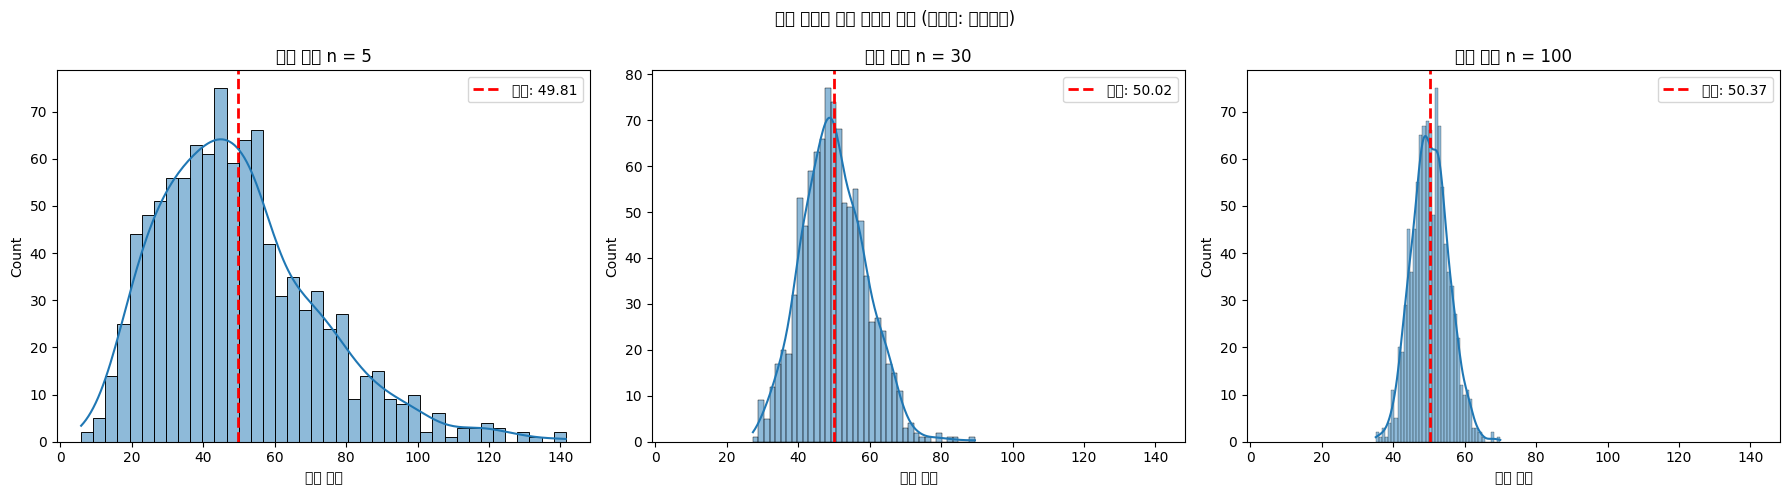

In [11]:
# [문제 2] Q3. 각 표본 크기별로 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 평균선을 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
results = {5: sample_means_5, 30: sample_means_30, 100: sample_means_100}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

for ax, (n, means) in zip(axes, results.items()):
    mean_val = np.mean(means)
    sns.histplot(means, bins=40, kde=True, ax=ax)
    ax.axvline(mean_val, color='red', linestyle='--', linewidth=2,
               label=f"평균: {mean_val:.2f}")
    ax.set_title(f"표본 크기 n = {n}")
    ax.set_xlabel("표본 평균")
    ax.legend()

plt.suptitle("표본 크기별 표본 평균의 분포 (모집단: 지수분포)")
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을 때 (예: 5), 평균들의 분포는 어떤 모양인가요?

- 표본 크기가 커질수록 평균 분포의 모양은 어떤 변화를 보이나요?

- 원래 모집단은 비대칭이었는데, 왜 평균들의 분포는 정규분포처럼 바뀌었을까요?

- 이 실험을 통해 중심극한정리를 어떻게 이해하게 되었나요?

- 표본 크기에 따라 **분포의 넓이(흩어짐)**는 어떻게 달라지나요?

In [12]:
# [문제 2]데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 1. 지수 분포 모양이다.
# 2. 정규 분포
# 3. 표본 크기가 커질수록 중심극한정리에 의해 정규 분포에 가까워진다.
# 4. 모집단이 어떤 모양이든 표본 크기가 커지면 표본 평균의 분포는 
#    평균이 모평균이고 정규분포에 가까운 형태가 된다는 것입니다.
# 5. 표본크기가 커질수록 분포의 넓이는 작아진다.


# 문제 3. 표준오차

**📘 문제**

- 앞선 실습에서 우리는 **표본 크기(n)가 커질수록 표본 평균들의 분포가 더 좁아진다**는 것을 확인했습니다.
- 이처럼 표본 평균들이 얼마나 흩어져 있는지(분포의 퍼진 정도)를 나타내는 값을 **표준오차(Standard Error, SE)**라고 부릅니다.
- 표준오차는 **표본 평균들의 표준편차**와 같은 의미이며, 이는 우리가 뽑은 표본 평균이 실제 모평균과 평균적으로 얼마나 떨어져 있을지를 나타내는 **'예상 오차의 크기'**입니다.

- 통계학적으로 이 표준오차는 **`SE = σ / √n`** (모집단 표준편차 / 표본 크기의 제곱근) 이라는 공식으로 계산할 수 있습니다.
- 이 공식은 **표본 크기(n)가 커질수록 표준오차(SE)가 작아진다**는 것을 명확히 보여줍니다.

- 이번 실습에서는 여러 크기의 표본을 뽑아, 시뮬레이션을 통해 얻은 **표본 평균들의 표준편차(실험값)**가 공식으로 계산한 **표준오차(이론값)**와 얼마나 일치하는지 직접 확인해봅니다.

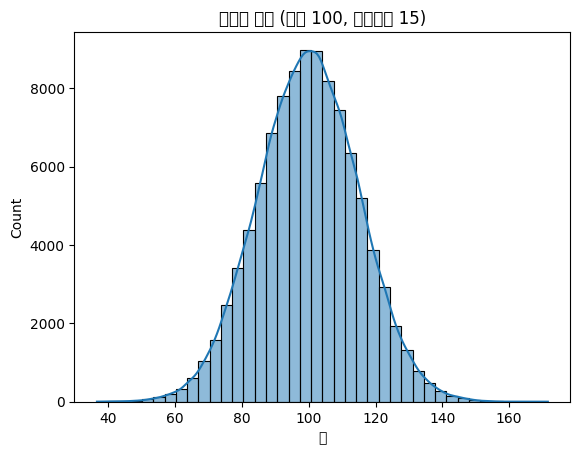

In [13]:
# 표준오차: 표준오차는 표본 평균이 표본마다 얼마나 흔들리는지를 나타내는 값이다.
# 모집단 생성 (평균 100, 표준편차 15)
np.random.seed(2025)
population = np.random.normal(loc=100, scale=15, size=100000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 100, 표준편차 15)")
plt.xlabel("값")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 여러 크기의 표본(10, 30, 100, 500)을 각각 1000번 뽑고, 그 평균들을 구한 뒤, **표본 평균들의 표준편차(=실험적 표준오차)**를 계산해봅시다.

- 이 결과를 이론적인 표준오차 공식과 비교하는 표를 만들고, 시각화해봅시다.

In [14]:
# [문제 3] Q1. 표본 크기 10, 30, 100, 500에 대해 각각 1000번 표본을 뽑고, 평균을 구해봅시다.
# 각 표본 평균 분포의 표준편차를 계산해봅시다.
# 결과를 리스트에 저장하고, 표로 정리해봅시다.

# 여기에 코드를 작성해주세요.
sample_sizes = [10, 30, 100, 500]
all_means = {}       # 표본 크기별 표본 평균 저장
empirical_se = []    # 실험으로 구한 표준편차 저장

for n in sample_sizes:
    means = []
    for i in range(1000):
        sample = np.random.choice(population, size=n)
        means.append(sample.mean())
    all_means[n] = means
    empirical_se.append(np.std(means))
    print(f"n = {n:>3} | 표본 평균들의 표준편차: {np.std(means):.3f}")

n =  10 | 표본 평균들의 표준편차: 4.662
n =  30 | 표본 평균들의 표준편차: 2.817
n = 100 | 표본 평균들의 표준편차: 1.512
n = 500 | 표본 평균들의 표준편차: 0.665


In [15]:
# [문제 3] Q2. 이론적인 표준오차와 비교해봅시다.
# [공식] 표준오차(SE) = 모집단 표준편차 / √표본크기

# 여기에 코드를 작성해주세요.
pop_std = population.std()   # 모집단 표준편차 (약 15)
theoretical_se = []

for n in sample_sizes:
    theoretical_se.append(pop_std / np.sqrt(n))

df_se = pd.DataFrame({
    '표본 크기': sample_sizes,
    '실험 표준편차': empirical_se,
    '이론 표준오차': theoretical_se
})
df_se['차이'] = df_se['실험 표준편차'] - df_se['이론 표준오차']
df_se = df_se.round(3)

print(f"모집단 표준편차: {pop_std:.3f}")
df_se

모집단 표준편차: 15.033
   표본 크기  실험 표준편차  이론 표준오차   차이
0         10          4.662          4.754 -0.091
1         30          2.817          2.745  0.073
2        100          1.512          1.503  0.008
3        500          0.665          0.672 -0.008


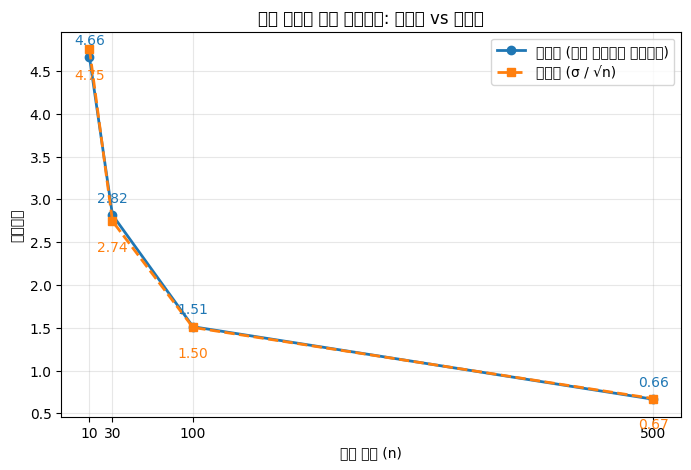

In [16]:
# [문제 3] Q3. 실험값과 이론값을 시각화해봅시다.
# 표본 크기를 x축, 표준오차를 y축으로 한 꺾은선 그래프를 그려봅시다.

# 여기에 코드를 작성해주세요.
plt.figure(figsize=(8, 5))

plt.plot(sample_sizes, empirical_se, marker='o', linewidth=2, label='실험값 (표본 평균들의 표준편차)')
plt.plot(sample_sizes, theoretical_se, marker='s', linestyle='--', linewidth=2, label='이론값 (σ / √n)')

# 각 점에 값 표시
for n, emp, theo in zip(sample_sizes, empirical_se, theoretical_se):
    plt.text(n, emp + 0.15, f"{emp:.2f}", ha='center', color='C0')
    plt.text(n, theo - 0.35, f"{theo:.2f}", ha='center', color='C1')

plt.title("표본 크기에 따른 표준오차: 실험값 vs 이론값")
plt.xlabel("표본 크기 (n)")
plt.ylabel("표준오차")
plt.xticks(sample_sizes)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을수록, 표본 평균의 분포는 어떤 모양인가요? 넓게 퍼져 있나요?

- 표본 크기가 커질수록, 평균 분포는 어떻게 변하나요?

- 실험값과 이론값(공식 계산값)은 얼마나 비슷한가요?

- 왜 표본 크기가 커질수록 표준오차는 작아질까요?

In [17]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.


1. 표본크기가 작을 수록 넓게 퍼진다.
2. 표본 크기가 커질수록 평균 분포는 정규본포와 유사해지면서  분포가 뾰족해진다.
3. 표본 크키가 작으면 차이가 있지만 표본크기가 커질수록 값이 비슷해진다.
4. 표본이 클수록 높은 값과 낮은 값이 서로 상쇄될 기회가 많아지고, 극단적인 값 하나가 평균에 미치는 영향도 작아진다.

# 문제 4. 신뢰구간 계산과 해석

**📘 문제**

- 표본 평균은 모집단 평균을 추정하는 좋은 점 추정(Point Estimation) 값이지만, 표본오차 때문에 정확히 일치하지는 않습니다.

- 그래서 우리는 "모집단 평균이 아마 이 범위 안에 있을 것이다"라고 **구간으로 추정(Interval Estimation)**하는 것이 더 합리적입니다. 이때 사용하는 개념이 바로 **신뢰구간(Confidence Interval)**입니다.

- 신뢰구간은 표본평균 ± 오차범위 형태로 계산되며, 이 오차범위는 신뢰수준(예: 95%, 99%)과 표본오차에 의해 결정됩니다.

- 이번 실습에서는 **모집단 표준편차(σ)를 알 때(z-분포)**와 **모를 때(t-분포)**의 신뢰구간을 각각 계산해보고, 신뢰수준에 따라 구간의 폭이 어떻게 변하는지 확인해봅니다.

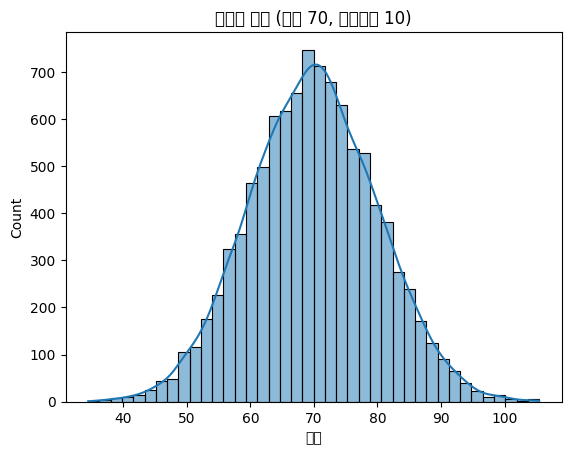

In [18]:
# 모집단 생성
np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 70, 표준편차 10)")
plt.xlabel("점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 30명을 무작위로 뽑아 평균, 표준편차, 표준오차를 계산해보세요.

- 95% 신뢰구간을 z-분포와 t-분포를 각각 사용해서 계산해보세요.

- 신뢰수준을 바꿨을 때(90%, 99%) 신뢰구간이 어떻게 변하는지 확인해보세요.

In [19]:
# [문제 4] Q1. 모집단에서 표본 30명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 표준오차도 함께 계산해보세요.

# 여기에 코드를 작성해주세요.
from scipy import stats

n = 30
sample = np.random.choice(population, size=n, replace=False)

sample_mean = sample.mean()
sample_std = sample.std(ddof=1)        # 표본 표준편차 (n-1로 나눔)
se = sample_std / np.sqrt(n)           # 표준오차

print(f"표본 평균: {sample_mean:.3f}")
print(f"표본 표준편차: {sample_std:.3f}")
print(f"표준오차: {se:.3f}")

표본 평균: 67.604
표본 표준편차: 11.078
표준오차: 2.023


In [20]:
# [문제 4] Q2. 모집단의 표준편차를 알고 있다고 가정하고, z-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

# 여기에 코드를 작성해주세요.
pop_std = population.std()             # 모집단 표준편차 (약 10)
se_z = pop_std / np.sqrt(n)

z = stats.norm.ppf(0.975)              # 95% → 양쪽 2.5%씩, z ≈ 1.96
lower_z = sample_mean - z * se_z
upper_z = sample_mean + z * se_z

print(f"z 값: {z:.3f}")
print(f"95% 신뢰구간 (z): [{lower_z:.3f}, {upper_z:.3f}]")
print(f"모집단 평균: {population.mean():.3f}")

z 값: 1.960
95% 신뢰구간 (z): [64.024, 71.184]
모집단 평균: 69.904


In [21]:
# [문제 4] Q3. 모집단의 표준편차를 모른다고 가정하고, 표본 표준편차와 t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

# 여기에 코드를 작성해주세요.
df = n - 1                              # 자유도
t = stats.t.ppf(0.975, df)              # 자유도 29일 때 t ≈ 2.045
lower_t = sample_mean - t * se
upper_t = sample_mean + t * se

print(f"t 값 (자유도 {df}): {t:.3f}")
print(f"95% 신뢰구간 (t): [{lower_t:.3f}, {upper_t:.3f}]")
print(f"모집단 평균: {population.mean():.3f}")

t 값 (자유도 29): 2.045
95% 신뢰구간 (t): [63.467, 71.740]
모집단 평균: 69.904


In [22]:
# [문제 4] Q4. 신뢰수준을 90%, 99%로 바꿔가며 신뢰구간을 계산해보고, 그 폭을 비교해봅시다.

# 여기에 코드를 작성해주세요.
conf_levels = [0.90, 0.95, 0.99]
results = []

for cl in conf_levels:
    alpha = 1 - cl
    z = stats.norm.ppf(1 - alpha / 2)
    t = stats.t.ppf(1 - alpha / 2, df)

    z_lower, z_upper = sample_mean - z * se_z, sample_mean + z * se_z
    t_lower, t_upper = sample_mean - t * se, sample_mean + t * se

    results.append({
        '신뢰수준': f"{int(cl*100)}%",
        'z 값': z, 'z 신뢰구간': f"[{z_lower:.2f}, {z_upper:.2f}]", 'z 폭': z_upper - z_lower,
        't 값': t, 't 신뢰구간': f"[{t_lower:.2f}, {t_upper:.2f}]", 't 폭': t_upper - t_lower,
    })

df_ci = pd.DataFrame(results).round(3)
df_ci

  신뢰수준   z 값      z 신뢰구간   z 폭   t 값      t 신뢰구간    t 폭
0      90%  1.645  [64.60, 70.61]  6.009  1.699  [64.17, 71.04]   6.873
1      95%  1.960  [64.02, 71.18]  7.160  2.045  [63.47, 71.74]   8.273
2      99%  2.576  [62.90, 72.31]  9.410  2.756  [62.03, 73.18]  11.150


**🧠 데이터를 어떻게 읽을까요?**

- z-분포와 t-분포를 사용한 신뢰구간은 얼마나 차이가 있나요?

- 신뢰수준이 높아질수록 신뢰구간의 폭은 어떻게 변하나요? 왜 그럴까요?

- 신뢰구간이 넓다는 건 좋은 걸까요? 나쁜 걸까요?

- 이 데이터가 실제 고객 만족도라면, 신뢰구간 정보를 마케팅 전략에 어떻게 활용할 수 있을까요?

In [23]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.


z-분포:z-분포는 평균이 0, 표준편차가 1인 정규분포입니다. 
t- 분포:t-분포는 모집단 표준편차를 모를 때, 표본 표준편차 s로 대신 계산할 때 따르는 분포입니다.
신뢰구간은 표본 데이터를 이용해 모집단의 값을 추정하는 범위입니다


1. t-분포는 모집단 표준편차를 모르고 표본으로 추정하는 불확실성까지 반영하기 때문에 꼬리가 조금 더 두껍고, 그만큼 구간이 약간 넓습니다. 표본 크기가 커질수록 t-분포는 z-분포에 가까워져서 차이가 거의 사라지고, 반대로 표본이 작을수록 차이가 커집니다.
2. 신뢰수준이 높아질수록 신뢰구간의 폭은 넓어진다. 신뢰수준이 높을수록 꼬리부분에서 잘자내는 부분이 작어지고 그만큼 곱해주는 값이 커진다.
3. 신뢰구간이 넓으면 모평균을 포함할 가능성이 높아 틀릴 위험은 작지만 너무 넓으면 실제 의사결정에 쓸 정보가 거의 없다. 반대로 좁으면 정밀하지만 틀릴 위험 커진다.
4.조사 규모를 정할 수 있습니다. 구간이 너무 넓어서 판단이 어렵다면 다음 설문 조사에서 표본을 얼마나 늘려야 원하는 정밀도를 얻을 수 있는지 미리 계산할 수 있습니다.

# 문제 5. 미니 프로젝트 - 고객 만족도 신뢰구간 추정

**📘 문제**

- 전체 고객 10,000명을 대상으로 만족도 조사를 하는 것은 시간과 비용이 많이 듭니다.
- 그래서 우리는 무작위로 일부 고객만 조사하여, 전체 고객의 평균 만족도를 추정하려 합니다.

- 이 프로젝트에서는 실제와 같은 상황을 가정하여, 표본을 뽑고 신뢰구간을 계산한 뒤, 이 결과를 바탕으로 마케팅 전략에 어떻게 활용할 수 있을지까지 생각해보는 실습을 진행합니다.

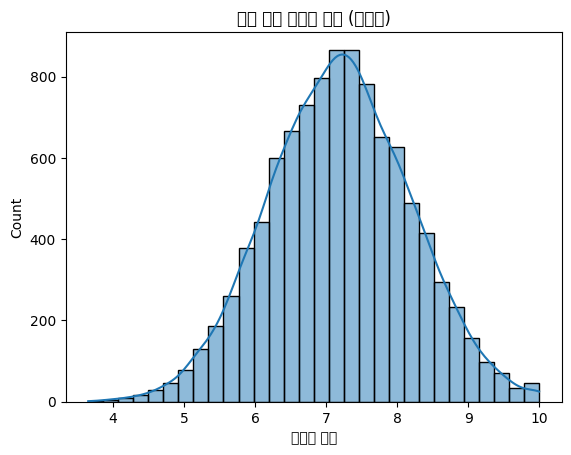

In [24]:
# 모집단 생성 (고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.2, scale=1.0, size=10000)
population = np.clip(population, 1, 10)

# 모집단 시각화
sns.histplot(population, bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단을 생성하고, 거기서 표본을 40명 뽑아 평균을 계산해봅시다.

- 표본 평균과 표준편차를 바탕으로 95% 신뢰구간을 계산해봅시다.

- 히스토그램을 그리고 신뢰구간을 시각화해봅시다.

- 이 결과를 어떻게 해석하고, 마케팅 전략에 활용할 수 있을지 생각해봅시다.

In [25]:
# [문제 5] Q1. 모집단에서 표본 40명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 여기에 코드를 작성해주세요.
from scipy import stats

n = 5000
sample = np.random.choice(population, size=n, replace=False)

sample_mean = sample.mean()
sample_std = sample.std(ddof=1)   # 표본 표준편차

print(f"표본 평균: {sample_mean:.3f}")
print(f"표본 표준편차: {sample_std:.3f}")



표본 평균: 7.176
표본 표준편차: 0.992


In [26]:
# [문제 5] Q2. 표준오차(SE)를 구하고, t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
# 여기에 코드를 작성해주세요.
se = sample_std / np.sqrt(n)
df = n - 1
t = stats.t.ppf(0.975, df)        # 자유도 39일 때 t ≈ 2.023

lower = sample_mean - t * se
upper = sample_mean + t * se

print(f"표준오차: {se:.3f}")
print(f"t 값 (자유도 {df}): {t:.3f}")
print(f"95% 신뢰구간: [{lower:.3f}, {upper:.3f}]")
print(f"모집단 평균: {population.mean():.3f}")


표준오차: 0.014
t 값 (자유도 4999): 1.960
95% 신뢰구간: [7.149, 7.204]
모집단 평균: 7.190


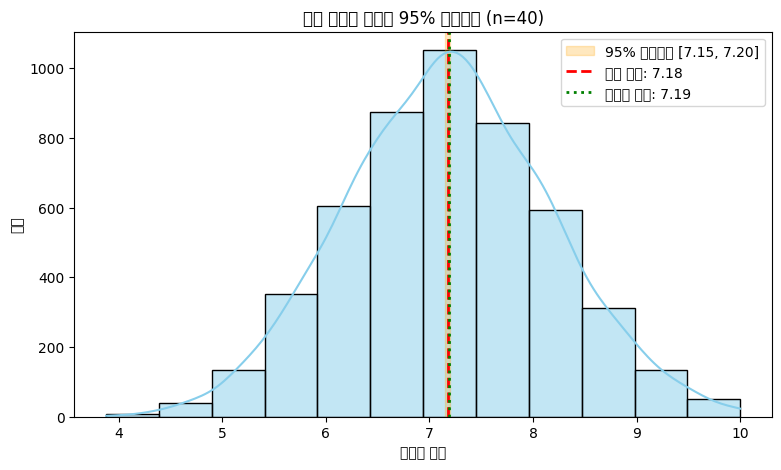

In [27]:
# [문제 5] Q3. 표본 데이터의 히스토그램을 그리고, 평균 및 신뢰구간을 함께 시각화해봅시다.
#  여기에 코드를 작성해주세요.
plt.figure(figsize=(9, 5))
sns.histplot(sample, bins=12, kde=True, color='skyblue')

# 신뢰구간 영역 음영 표시
plt.axvspan(lower, upper, color='orange', alpha=0.25,
            label=f"95% 신뢰구간 [{lower:.2f}, {upper:.2f}]")
plt.axvline(sample_mean, color='red', linestyle='--', linewidth=2,
            label=f"표본 평균: {sample_mean:.2f}")
plt.axvline(population.mean(), color='green', linestyle=':', linewidth=2,
            label=f"모집단 평균: {population.mean():.2f}")

plt.title("표본 만족도 분포와 95% 신뢰구간 (n=40)")
plt.xlabel("만족도 점수")
plt.ylabel("빈도")
plt.legend()
plt.show()


In [28]:
# [문제 5] Q4. 신뢰구간의 결과에 따라 어떤 구체적인 마케팅 전략을 세울 수 있을까요?
# 여기에 의견을 작성해주세요.
target = 7.0   # 회사의 만족도 목표 점수 (상황에 맞게 변경)

print(f"95% 신뢰구간: [{lower:.2f}, {upper:.2f}], 목표: {target}")

if lower > target:
    print("→ 목표 달성이 통계적으로 확실함")
    print("  전략: 높은 만족도를 마케팅 메시지로 활용(후기·평점 강조), 충성 고객 대상 추천 프로그램 확대")
elif upper < target:
    print("→ 목표 미달이 통계적으로 확실함")
    print("  전략: 불만 요인 조사(추가 설문, 리뷰 분석), 서비스 개선 후 재측정, 이탈 위험 고객 대상 보상 쿠폰 제공")
else:
    print("→ 목표가 신뢰구간 안에 있어 달성 여부가 불확실함")
    print("  전략: 표본을 늘려 재조사, 소규모 개선 캠페인을 테스트(A/B 테스트)한 뒤 효과 확인")

95% 신뢰구간: [7.15, 7.20], 목표: 7.0
→ 목표 달성이 통계적으로 확실함
  전략: 높은 만족도를 마케팅 메시지로 활용(후기·평점 강조), 충성 고객 대상 추천 프로그램 확대


**🧠 데이터를 어떻게 읽을까요?**

- 신뢰구간은 몇 점에서 몇 점 사이인가요?

- 이 구간은 전체 모집단 평균을 포함하고 있나요?

- 이 결과를 바탕으로 고객 만족도가 충분히 높다고 말할 수 있을까요?

- 만약 신뢰구간이 너무 넓게 나왔다면, 그 이유는 무엇이고 어떻게 개선할 수 있을까요?

In [29]:
# [문제 5] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

1.신뢰구간: [6.793, 7.496]

2.신리구간 [6.793, 7.496] 사이에 모집단의 평균 7.190 가 들어간다.

3. 목표점수에 따라 고객 만족도가 높다/낮다라고 말할 수 있을 것 같다.  신뢰구간안에 목표점수가 들어와도 달성여부가 불확실할 
수 있다.

4. 표본 크기가 작은 경우, 표본크기가 작으면 표준오차가 커지고 t값도 커진다. 표본크기를 키우면 폭을 줄일 수 있다.